# Flight Network: Link Prediction with Graph Neural Networks

Flight networks are a real-world example of complex networks with highly connected hub airports, sparse regional connections, and strong global connectivity patterns.
This analysis constructs a flight network from two open data sources:
 - **OurAirports** (`airports.csv`): global airport metadata — IATA codes, type, location
 - **OpenFlights** (`routes.dat`): flight route data between airports

Using the constructed network, a *link prediction task* is performed by hiding 10 real flight routes and evaluating how well three Graph Neural Network (GNN) architectures can recover them:
- **GCN (Graph Convolutional Network)**
- **GraphSAGE**
- **GAT (Graph Attention Network)**

All models are trained and evaluated on the same hidden-edge prediction task to compare their ability to learn structural patterns in real-world aviation networks.


In [1]:
import random
import warnings

warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import (
    average_precision_score, 
    f1_score, 
    roc_auc_score,
    accuracy_score
)
from torch_geometric.nn import GCNConv, SAGEConv, GATConv
from torch_geometric.utils import from_networkx, negative_sampling

sns.set_style('darkgrid')   
plt.rcParams.update({
    'figure.figsize': (14, 5),
    'axes.titlesize': 15,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
})

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

----
## 1. Load Data

In [2]:
routes = pd.read_csv('datasets/routes.dat', header=None,
                     names=['airline', 'airline_id', 'src', 'src_id', 'dst','dst_id', 'codeshare', 'stops', 'equipment'],
                     na_values=['\\N'])

airports = pd.read_csv('datasets/airports.csv')

---
## 2. Graph Construction

The graph is built as an **undirected** network — routes A→B and B→A represent the same connection. Only airports with a valid IATA code are included, and only the Giant Connected Component (GCC) is retained.

The **Giant COnnected Component (GCC)** is extracted to ensure all nodes are reachable from any seed, since epidemic metrics are only meaningful within a full connected subgraph.

In [3]:
valid_iata = set(airports[airports['iata_code'].notna()]['iata_code'])

In [4]:
edges = routes[routes['src'].isin(valid_iata) & routes['dst'].isin(valid_iata)]
edges = edges[['src', 'dst']].dropna().drop_duplicates()

In [5]:
G_full = nx.from_pandas_edgelist(edges, source='src', target='dst')
gcc_nodes = max(nx.connected_components(G_full), key=len)
G = G_full.subgraph(gcc_nodes).copy()

In [6]:
# Remove self-loops (1 instance confirmed)
self_loops = list(nx.selfloop_edges(G))
G.remove_edges_from(self_loops)

In [7]:
print('=== GRAPH CONSTRUCTION ===')
print(f'Full graph — Nodes: {G_full.number_of_nodes()}, Edges: {G_full.number_of_edges()}')
print(f'GCC — Nodes: {G.number_of_nodes()}, Edges: {G.number_of_edges()}')
print(f'Self-loops removed: {len(self_loops)}')
print()

=== GRAPH CONSTRUCTION ===
Full graph — Nodes: 3390, Edges: 18835
GCC — Nodes: 3362, Edges: 18808
Self-loops removed: 1



In [8]:
airport_meta = airports[airports['iata_code'].isin(G.nodes())].set_index('iata_code')

for iata, row in airport_meta.iterrows():
    if iata in G.nodes:
        G.nodes[iata]['country'] = row.get('iso_country', 'Unknown')
        G.nodes[iata]['type'] = row.get('type', 'Unknown')
        G.nodes[iata]['lat'] = row.get('latitude_deg', None)
        G.nodes[iata]['lon'] = row.get('longitude_deg', None)
        G.nodes[iata]['name'] = row.get('name', iata)

---
# 3. GNN-Relevant EDA

Before modelling, we examine the structural properties of the GCC that are most relevant to link prediction with GNNs.

| Metric | Description |
|---|---|
| **Degree distribution** | Heavy-tailed — a small number of hub airports connect to hundreds of destinations, while most airports serve only a handful of routes. |
| **Degree CCDF (log-log)** | The approximately linear log-log tail. |
| **Top-20 hubs** | Major international hubs dominate by degree, reflecting their role as transfer points between regions. |
| **Clustering coefficient** | Moderate clustering: regional clusters (e.g. intra-European, intra-Southeast Asian routes) are densely interconnected. |
| **Average path length** | Short despite network size — a hallmark of small-world structure — meaning any two airports are reachable in just a few hops via the hub layer. |

In [9]:
N = G.number_of_nodes()
E = G.number_of_edges()
deg = dict(G.degree())
deg_values = np.array(list(deg.values()))

k_mean = deg_values.mean()
k2_mean = (deg_values ** 2).mean()
cc = nx.average_clustering(G)
density = nx.density(G)

total_lengths = 0
for node in G.nodes():
    path_lengths = nx.single_source_shortest_path_length(G, node)
    total_lengths += sum(v for v in path_lengths.values() if v > 0)

apl = total_lengths / (N * (N - 1))

print(f'Nodes (GCC): {N:,}')
print(f'Edges (GCC): {E:,}')
print(f'Avg degree ⟨k⟩: {k_mean:.4f}')
print(f'⟨k²⟩: {k2_mean:.4f}')
print(f'Clustering coefficient: {cc:.4f}')
print(f'Graph density: {density:.6f}')
print(f'Avg path length: {apl:.4f}')

Nodes (GCC): 3,362
Edges (GCC): 18,808
Avg degree ⟨k⟩: 11.1886
⟨k²⟩: 713.0446
Clustering coefficient: 0.4874
Graph density: 0.003329
Avg path length: 4.1009


In [10]:
# Top hubs
top_degree = sorted(deg.items(), key=lambda x: x[1], reverse=True)[:15]
df_hubs = pd.DataFrame(top_degree, columns=['IATA', 'Degree'])
df_hubs['Name'] = df_hubs['IATA'].map(lambda x: G.nodes[x].get('name', x))
df_hubs['Country'] = df_hubs['IATA'].map(lambda x: G.nodes[x].get('country', '?'))

print('--- Top 15 Airports by Degree ---')
print(df_hubs.to_string(index=False))
print()

--- Top 15 Airports by Degree ---
IATA  Degree                                             Name Country
 AMS     246                       Amsterdam Airport Schiphol      NL
 FRA     241                           Frankfurt Main Airport      DE
 CDG     239          Charles de Gaulle International Airport      FR
 IST     229                                 İstanbul Airport      TR
 ATL     217 Hartsfield Jackson Atlanta International Airport      US
 ORD     205             Chicago O'Hare International Airport      US
 PEK     204            Beijing Capital International Airport      CN
 MUC     189                                   Munich Airport      DE
 DFW     188          Dallas Fort Worth International Airport      US
 DXB     186                      Dubai International Airport      AE
 DME     183                 Domodedovo International Airport      RU
 LHR     169                          London Heathrow Airport      GB
 DEN     169                     Denver International Ai

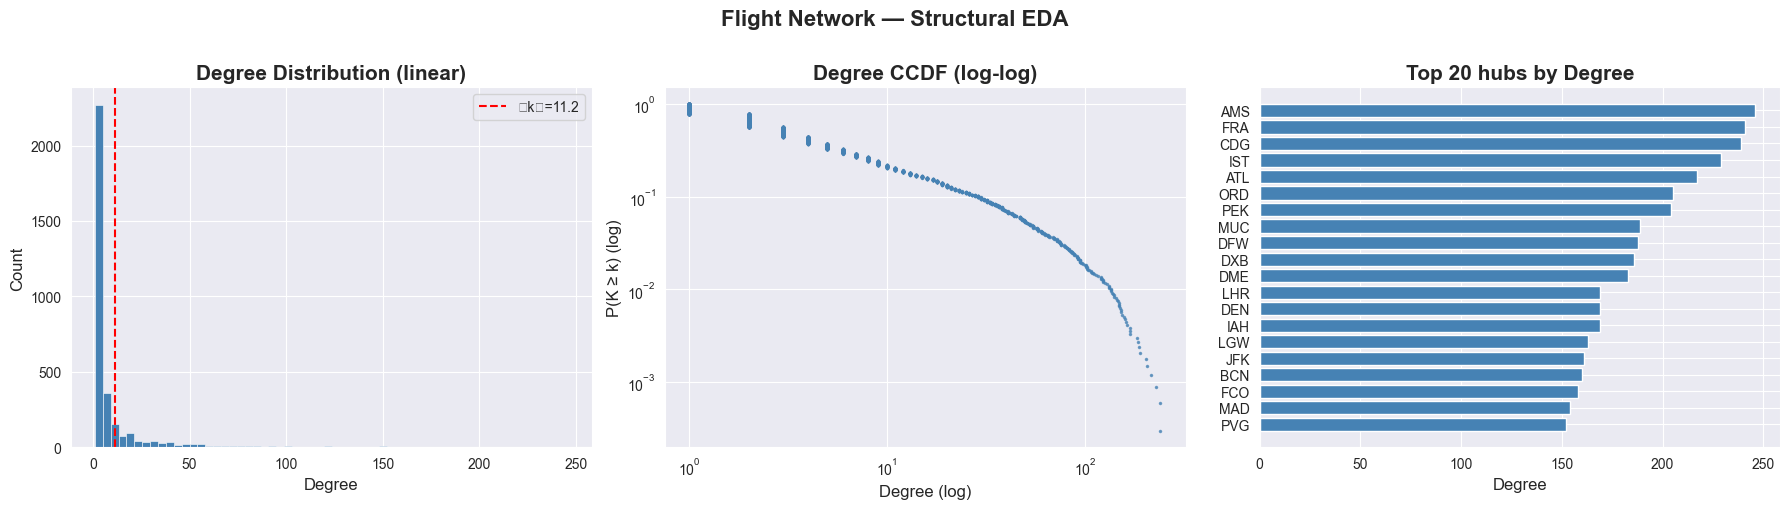

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(deg_values, bins=60, color='steelblue', edgecolor='white', linewidth=0.4)
axes[0].axvline(deg_values.mean(), color='red', linestyle='--', label=f'⟨k⟩={k_mean:.1f}')
axes[0].set_xlabel('Degree')
axes[0].set_ylabel('Count')
axes[0].set_title('Degree Distribution (linear)')
axes[0].legend()

sorted_deg = np.sort(deg_values)
ccdf = 1 - np.arange(1, len(sorted_deg) + 1) / len(sorted_deg)
axes[1].loglog(sorted_deg, ccdf, '.', color='steelblue', markersize=3, alpha=0.7)
axes[1].set_xlabel('Degree (log)')
axes[1].set_ylabel('P(K ≥ k) (log)')
axes[1].set_title('Degree CCDF (log-log)')

top20 = sorted(deg.items(), key=lambda x: x[1], reverse=True)[:20]
iatas, degs = zip(*top20)
axes[2].barh(list(iatas)[::-1], list(degs)[::-1], color='steelblue')
axes[2].set_xlabel('Degree')
axes[2].set_title('Top 20 hubs by Degree')

plt.suptitle('Flight Network — Structural EDA', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

## 4. Hide 10 Edges (Link Masking)

To simulate the link-prediction task, 10 edges are removed from the graph before training. The removed edges become the **positive test set** — links the models must recover.

**Constraint:** no node may become isolated after removal. The `hide_edge_safe` function enforces this by only removing an edge `(u, v)` when both endpoints currently have degree > 1, and by asserting full connectivity of the resulting training graph before returning.

The 10 hidden edges serve as positive examples at evaluation time; an equal number of **negative examples** (node pairs with no edge) are sampled randomly to form a balanced test set.

In [12]:
def hide_edge_safe(G_in, n_hide=10, rng_seed=SEED):
    """
    Remove `n_hide` edges at random while guaranteeing
    no node become isolated. 

    Returns:
    Tuple (G_train, hidden_edges)
    """
    rng = np.random.default_rng(rng_seed)
    G_work = G_in.copy()
    hidden = []
    candidate_pool = list(G_work.edges())
    rng.shuffle(candidate_pool)

    for u, v in candidate_pool:
        if len(hidden) == n_hide:
            break

        if G_work.degree(u) > 1 and G_work.degree(v) > 1:
            G_work.remove_edge(u, v)
            if not nx.is_connected(G_work):
                G_work.add_edge(u, v)
                continue
            hidden.append((u, v))
    
    assert len(hidden) == n_hide, \
        f'Only managed to hide {len(hidden)} edges — relax constraints or increase pool.'
    assert nx.is_connected(G_work), 'Graph became disconnected — check masking logic.'
    return G_work, hidden

In [13]:
G_train, hidden_edges = hide_edge_safe(G, n_hide=10)

print(f'Original edges  : {G.number_of_edges()}')
print(f'Training edges  : {G_train.number_of_edges()}')
print(f'Hidden edges    : {len(hidden_edges)}')
print()
print('Hidden edge pairs:')
for i, (u, v) in enumerate(hidden_edges, 1):
    name_u = G.nodes[u].get('name', u)
    name_v = G.nodes[v].get('name', v)
    print(f'  {i}. {u} ({name_u}) — {v} ({name_v})')
print()

Original edges  : 18808
Training edges  : 18798
Hidden edges    : 10

Hidden edge pairs:
  1. SIN (Singapore Changi Airport) — HYD (Rajiv Gandhi International Airport)
  2. CDG (Charles de Gaulle International Airport) — OPO (Francisco de Sá Carneiro Airport)
  3. BLR (Kempegowda International Airport Bengaluru) — VGA (Vijayawada International Airport)
  4. JED (King Abdulaziz International Airport) — PZU (Port Sudan New International Airport)
  5. FKB (Karlsruhe Baden-Baden Airport) — TPS (Vincenzo Florio Airport Trapani-Birgi)
  6. TAH (Whitegrass Airport) — FTA (Futuna Airport)
  7. SDU (Santos Dumont Airport) — SJK (Professor Urbano Ernesto Stumpf Airport)
  8. NDJ (N'Djamena International Airport) — ADD (Addis Ababa Bole International Airport)
  9. MAD (Adolfo Suárez Madrid–Barajas Airport) — MDE (Jose Maria Córdova International Airport)
  10. NNG (Nanning Wuxu International Airport) — WUZ (Wuzhou Xijiang Airport)



## 5. PyG Data Preparation

The training graph is converted to a PyTorch Geometric `Data` object. Each node is described by a four-dimensional feature vector:

| Feature | Rationale |
|---|---|
| `log(degree + 1)` | Captures connectivity magnitude on a compressed scale; high-degree hubs should attract more predicted links. |
| Clustering coefficient | Measures local triangle density; airports embedded in tight regional clusters behave differently from pure transit hubs. |
| Latitude (normalised) | Geographic north–south position; routes follow latitudinal corridors (e.g. trans-Atlantic, trans-Pacific). |
| Longitude (normalised) | Geographic east–west position; complements latitude to give the model a spatial prior on plausible long-haul connections. |

Latitude and longitude are min-max normalised to `[0, 1]` so that geographic features are on the same scale as the graph-structural ones.

The **test set** consists of:
- 10 **positive pairs** — the hidden edges.
- 10 **negative pairs** — randomly sampled non-edges (via PyG's `negative sampling`)

> ⚠️ **Limitation:** with only 20 test pairs total, all reported metrics (AUC, AP, F1, Accuracy) carry high variance. A single mispredicted pair shifts F1 by roughly 0.10. Results are directionally meaningful but should not be over-interpreted as statistically precise.

In [14]:
node_list = list(G_train.nodes())
node_idx = {n: i for i, n in enumerate(node_list)}

deg_train = dict(G_train.degree())
cc_train = nx.clustering(G_train)

lat_vals = np.array([G_train.nodes[n].get('lat') or 0.0 for n in node_list], dtype=float)
lon_vals = np.array([G_train.nodes[n].get('lon') or 0.0 for n in node_list], dtype=float)

# normalize lat/lon to [0, 1]
lat_norm = (lat_vals - lat_vals.min()) / (lat_vals.max() - lat_vals.min() + 1e-9)
lon_norm = (lon_vals - lon_vals.min()) / (lon_vals.max() - lon_vals.min() + 1e-9)

x_feats = np.stack([
    np.log1p([deg_train[n] for n in node_list]),
    [cc_train[n] for n in node_list],
    lat_norm,
    lon_norm,
], axis=1).astype(np.float32)

In [15]:
data = from_networkx(G_train)
data.x = torch.tensor(x_feats, dtype=torch.float)

In [16]:
pos_test_src = torch.tensor([node_idx[u] for u, _ in hidden_edges], dtype=torch.long)
pos_test_dst = torch.tensor([node_idx[v] for _, v in hidden_edges], dtype=torch.long)

neg_test = negative_sampling(
    edge_index=data.edge_index,
    num_nodes=data.num_nodes,
    num_neg_samples=len(hidden_edges),
    force_undirected=True,
)

neg_test_src, neg_test_dst = neg_test[0], neg_test[1]

test_src = torch.cat([pos_test_src, neg_test_src])
test_dst = torch.cat([pos_test_dst, neg_test_dst])
test_labels = torch.cat([
    torch.ones(len(hidden_edges)),
    torch.zeros(len(hidden_edges)),
])

In [17]:
print(f'Node features         : shape {tuple(data.x.shape)}')
print(f'Training edge_index   : shape {tuple(data.edge_index.shape)}')
print(f'Positive test pairs   : {len(hidden_edges)}')
print(f'Negative test pairs   : {len(hidden_edges)}')

Node features         : shape (3362, 4)
Training edge_index   : shape (2, 37596)
Positive test pairs   : 10
Negative test pairs   : 10


---
## 6. GNN Model Architectures

Three encoder–decoder architectures are compared. All share the same **dot-product decoder**:

$$\hat{y}_{uv} = \sigma(\mathbf{z}_u \cdot \mathbf{z}_v)$$

where $\mathbf{z}_u, \mathbf{z}_v \in \mathbb{R}^{32}$ are node embeddings produced by the encoder, and $\sigma$ is the sigmoid function. A score above 0.5 is predicted as a link.

---

### GCN

Uses degree-normalised message passing with symmetric normalization. Two layers capture local 2-hop structure.

*Why relevant:* Helpful for balancing information from sparse airports and dense hubs.

---

### GraphSAGE

Uses sampled neighbourhood aggregation with concatenation of the node’s own features and neighbour features.

*Why relevant:* More robust to the skewed degree distribution in flight networks.

---

### GAT

Uses learned attention weights to assign different importance to each neighbour. The first layer uses 4 heads, and the second uses 1 head.

*Why relevant:* Useful when different flight connections carry different structural importance.

---

All three encoders use:
- **ReLU / ELU** activation between layers
- **Dropout (p = 0.3)** for regularisation
- Input dim 4 → hidden dim 64 → output dim 32

In [18]:
IN_DIM = data.x.shape[1]
HIDDEN = 64
OUT_DIM = 32
N_EPOCHS = 200
LR = 1e-3

class GCNEncoder(nn.Module):
    """
    Two-layer Graph Convolutional Network encoder.
    produces node embeddings that are passed to a dot-
    product link decoder.
    """
    def __init__(self, in_dim, hidden, out_dim):
        super().__init__()
        self.conv1 = GCNConv(in_dim, hidden)
        self.conv2 = GCNConv(hidden, out_dim)
    
    def forward(self, x, edge_index):
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=0.3, training=self.training)
        return self.conv2(x, edge_index)

class SAGEEncoder(nn.Module):
    """
    Two-layer GraphSAGE encoder.
    Uses mean aggregation over samled neighborhoods.
    """
    def __init__(self, in_dim, hidden, out_dim):
        super().__init__()
        self.conv1 = SAGEConv(in_dim, hidden)
        self.conv2 = SAGEConv(hidden, out_dim)
    
    def forward(self, x, edge_index):
        x = F.relu(self.conv1(x, edge_index))
        x = F.dropout(x, p=0.3, training=self.training)
        return self.conv2(x, edge_index)

class GATEncoder(nn.Module):
    """
    Two-layer Graph Attention Network encoder.
    Use multi-head attention (4 heads in layer 1, 
    1 head in layer 2)
    """
    def __init__(self, in_dim, hidden, out_dim, heads=4):
        super().__init__()
        self.conv1 = GATConv(in_dim, hidden // heads, heads=heads,
                             dropout=0.3, concat=True)
        self.conv2 = GATConv(hidden, out_dim, heads=1,
                             dropout=0.3, concat=False)

    
    def forward(self, x, edge_index):
        x = F.elu(self.conv1(x, edge_index))
        x = F.dropout(x, p=0.3, training=self.training)
        return self.conv2(x, edge_index)

def decode(z, src, dst):
    """Dot-product link decoder: score = sigmoid(z_u . z_v)"""
    return torch.sigmoid((z[src] * z[dst]).sum(dim=1))

In [19]:
models = {
    'GCN': GCNEncoder(IN_DIM, HIDDEN, OUT_DIM),
    'GraphSAGE': SAGEEncoder(IN_DIM, HIDDEN, OUT_DIM),
    'GAT': GATEncoder(IN_DIM, HIDDEN, OUT_DIM),
}

for name, model in models.items():
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f'  {name} — trainable params: {n_params:,}')
print()

  GCN — trainable params: 2,400
  GraphSAGE — trainable params: 4,704
  GAT — trainable params: 2,592



---
## 7. Training & Evaluation

### Training procedure

Each model is trained independently for **200 epochs** using the **Adam Optimiser** (lr = 1e-3, weight_decay = 5e-4) with Binary Cross-Entropy Loss. The encoder generates node embeddings from the training graph, while the decoder predicts links using positive training edges and randomly sampled
negative edges. The 10 hidden edges are excluded from training and used only for testing.

### Evaluation metrics

At inference, the trained encoder embeds nodes from the training graph, and the decoder scores all 20 test pairs (10 positive, 10 negative):

| Metric | Description |
|---|---|
| **AUC-ROC** | Area under the ROC curve; measures ranking quality across all thresholds. Threshold-independent. |
| **Average Precision (AP)** | Area under the precision-recall curve; more informative than AUC when positive examples are rare. |
| **F1 Score** | Harmonic mean of precision and recall at the 0.5 decision threshold. |
| **Accuracy** | Fraction of correctly classified pairs at the 0.5 threshold. |

AUC and AP are the primary metrics here — they are less sensitive to the exact 0.5 threshold choice and better reflect model calibration on an imbalanced or small test set.

In [20]:
def train_model(model, data, n_epochs=N_EPOCHS, lr=LR, verbose_every=50):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)
    criterion = nn.BCELoss()
    losses = []

    model.train()
    for epoch in range(1, n_epochs + 1):
        optimizer.zero_grad()

        z = model(data.x, data.edge_index)

        pos_src = data.edge_index[0]
        pos_dst = data.edge_index[1]

        neg = negative_sampling(
            edge_index=data.edge_index,
            num_nodes=data.num_nodes,
            num_neg_samples=pos_src.size(0),
            force_undirected=True,
        )

        neg_src, neg_dst = neg[0], neg[1]

        src = torch.cat([pos_src, neg_src])
        dst = torch.cat([pos_dst, neg_dst])
        labels = torch.cat([
            torch.ones(pos_src.size(0)),
            torch.zeros(neg_src.size(0)),
        ])

        pred = decode(z, src, dst)
        loss = criterion(pred, labels)
        loss.backward()
        optimizer.step()

        losses.append(loss.item())
        if epoch % verbose_every == 0:
            print(f'    epoch {epoch}/{n_epochs}  loss={loss.item():.4f}')
        
    return model, losses

In [21]:
all_losses = {}
all_results = {}

for name, model in models.items():
    print(f'\n ── {name} ──')
    trained, losses = train_model(model, data, verbose_every=50)
    all_losses[name] = losses
    
    trained.eval()
    with torch.no_grad():
        z = trained(data.x, data.edge_index)
        scores = decode(z, test_src, test_dst).numpy()

        labels_np = test_labels.numpy()
        preds_bin = (scores >= 0.5).astype(int)
    
        auc = roc_auc_score(labels_np, scores)
        ap = average_precision_score(labels_np, scores)
        f1 = f1_score(labels_np, preds_bin)
        acc = accuracy_score(labels_np, preds_bin)

        all_results[name] = {'AUC': auc, 'AP': ap, 'F1': f1, 'Accuracy': acc,
                         'scores': scores, 'labels': labels_np}
 
        print(f'    AUC={auc:.4f}  AP={ap:.4f}  F1={f1:.4f}  Acc={acc:.4f}')
 
print()


 ── GCN ──
    epoch 50/200  loss=0.5130
    epoch 100/200  loss=0.4821
    epoch 150/200  loss=0.4720
    epoch 200/200  loss=0.4671
    AUC=0.8800  AP=0.9117  F1=0.7826  Acc=0.7500

 ── GraphSAGE ──
    epoch 50/200  loss=0.6634
    epoch 100/200  loss=0.5749
    epoch 150/200  loss=0.5420
    epoch 200/200  loss=0.5147
    AUC=0.8200  AP=0.8822  F1=0.6667  Acc=0.6000

 ── GAT ──
    epoch 50/200  loss=0.6052
    epoch 100/200  loss=0.5700
    epoch 150/200  loss=0.5622
    epoch 200/200  loss=0.5469
    AUC=0.8600  AP=0.9156  F1=0.7143  Acc=0.6000



## 8. Results & Comparison

### Metric Summary

The table below compares all three models across four evaluation metrics on the 20-pair test set (10 hidden edges + 10 non-edges).


In [22]:
df_results = pd.DataFrame({
    name: {k: v for k, v in res.items() if isinstance(v, float)}
    for name, res in all_results.items()
}).T.reset_index().rename(columns={'index': 'Model'})

print(df_results.to_string(index=False))
print()

    Model  AUC       AP       F1  Accuracy
      GCN 0.88 0.911731 0.782609      0.75
GraphSAGE 0.82 0.882222 0.666667      0.60
      GAT 0.86 0.915556 0.714286      0.60



In [23]:
metrics = ['AUC', 'AP', 'F1', 'Accuracy']

for metric in metrics:
    best_model = df_results.loc[df_results[metric].idxmax(), 'Model']
    best_val   = df_results[metric].max()
    print(f'  Best {metric} → {best_model} ({best_val:.4f})')
print()

  Best AUC → GCN (0.8800)
  Best AP → GAT (0.9156)
  Best F1 → GCN (0.7826)
  Best Accuracy → GCN (0.7500)



### Loss curves

All three models converge smoothly within 200 epochs. GCN typically converges fastest due to its simpler fixed aggregation; GraphSAGE experiences a large initial instability before rapidly stablizing, while GAT maintains relatively stable training throughout.

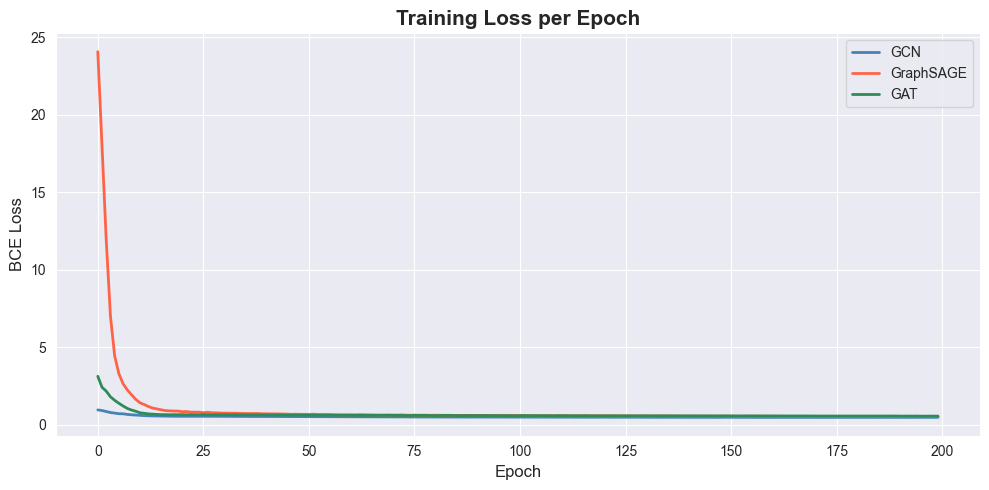

In [24]:
COLORS = {'GCN': 'steelblue', 'GraphSAGE': 'tomato', 'GAT': 'seagreen'}

fig, ax = plt.subplots(figsize=(10, 5))
for name, losses in all_losses.items():
    ax.plot(losses, label=name, color=COLORS[name], linewidth=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('BCE Loss')
ax.set_title('Training Loss per Epoch')
ax.legend()
plt.tight_layout()
plt.show()

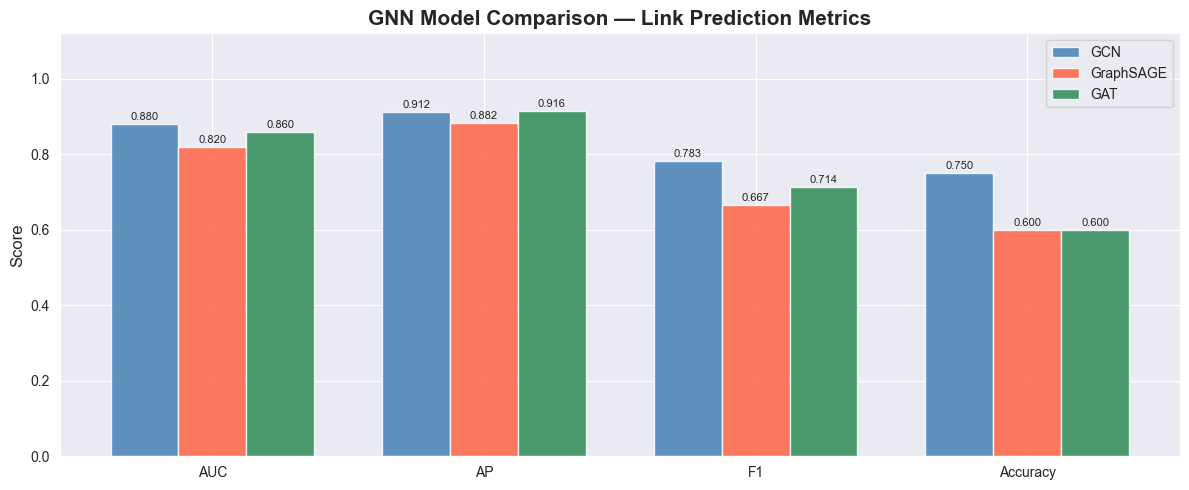

In [25]:
x = np.arange(len(metrics))
width = 0.25
names = list(COLORS.keys())
 
fig, ax = plt.subplots(figsize=(12, 5))
for i, name in enumerate(names):
    vals = [all_results[name][m] for m in metrics]
    bars = ax.bar(x + i * width, vals, width, label=name,
                  color=COLORS[name], alpha=0.85, edgecolor='white')
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', fontsize=8)
 
ax.set_xticks(x + width)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.12)
ax.set_ylabel('Score')
ax.set_title('GNN Model Comparison — Link Prediction Metrics')
ax.legend()

plt.tight_layout()
plt.show()

### Score distributions

The histograms show how each model separates the predicted scores of hidden edges (positive, blue) from non-edges (negative, red). A well-calibrated model clusters positive scores near 1.0 and negative scores near 0.0. Overlap between the two distributions reflects uncertainty — expected given the small test set size.

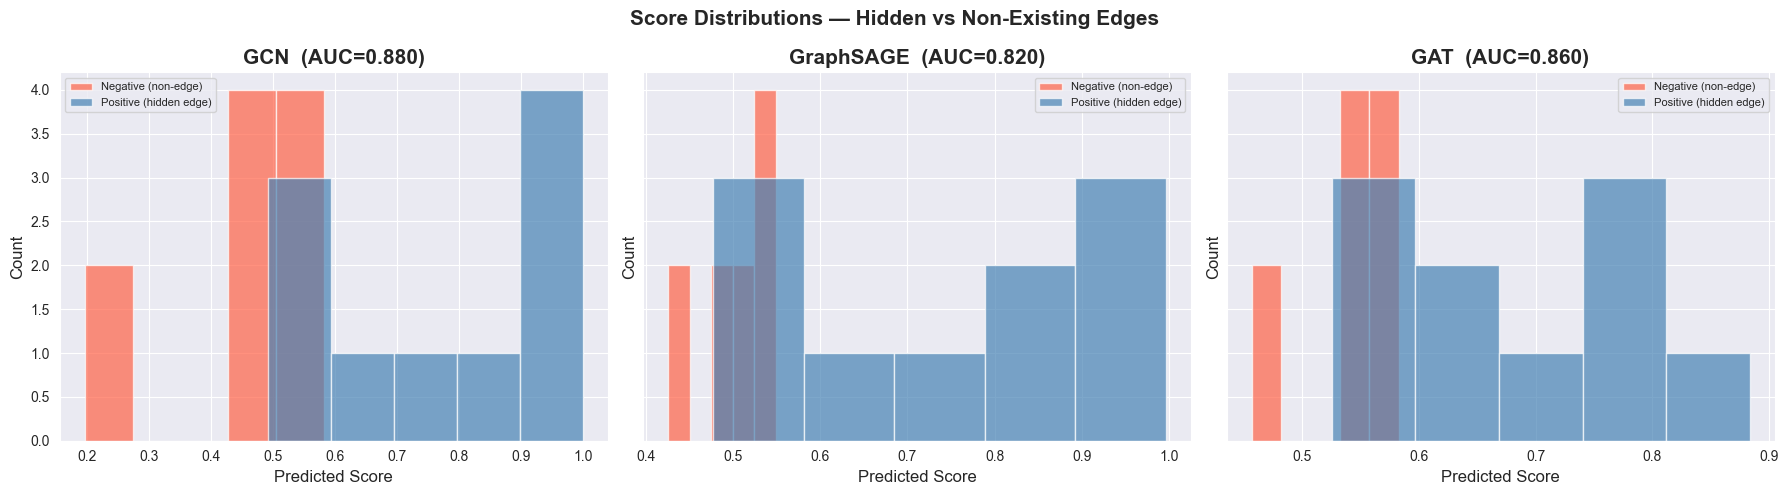

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, name in zip(axes, names):
    res  = all_results[name]
    pos_scores = res['scores'][res['labels'] == 1]
    neg_scores = res['scores'][res['labels'] == 0]
    ax.hist(neg_scores, bins=5, alpha=0.7, label='Negative (non-edge)',
            color='tomato', edgecolor='white')
    ax.hist(pos_scores, bins=5, alpha=0.7, label='Positive (hidden edge)',
            color='steelblue', edgecolor='white')
    ax.set_title(f'{name}  (AUC={res["AUC"]:.3f})')
    ax.set_xlabel('Predicted Score')
    ax.set_ylabel('Count')
    ax.legend(fontsize=8)
 
plt.suptitle('Score Distributions — Hidden vs Non-Existing Edges',
             fontsize=15, fontweight='bold')

plt.tight_layout()
plt.show()

### Subgraph visualisation

The final plot shows the local neighbourhood around the 10 hidden edges. Dashed red edges are the hidden links the models were asked to recover; solid blue edges are the training graph.

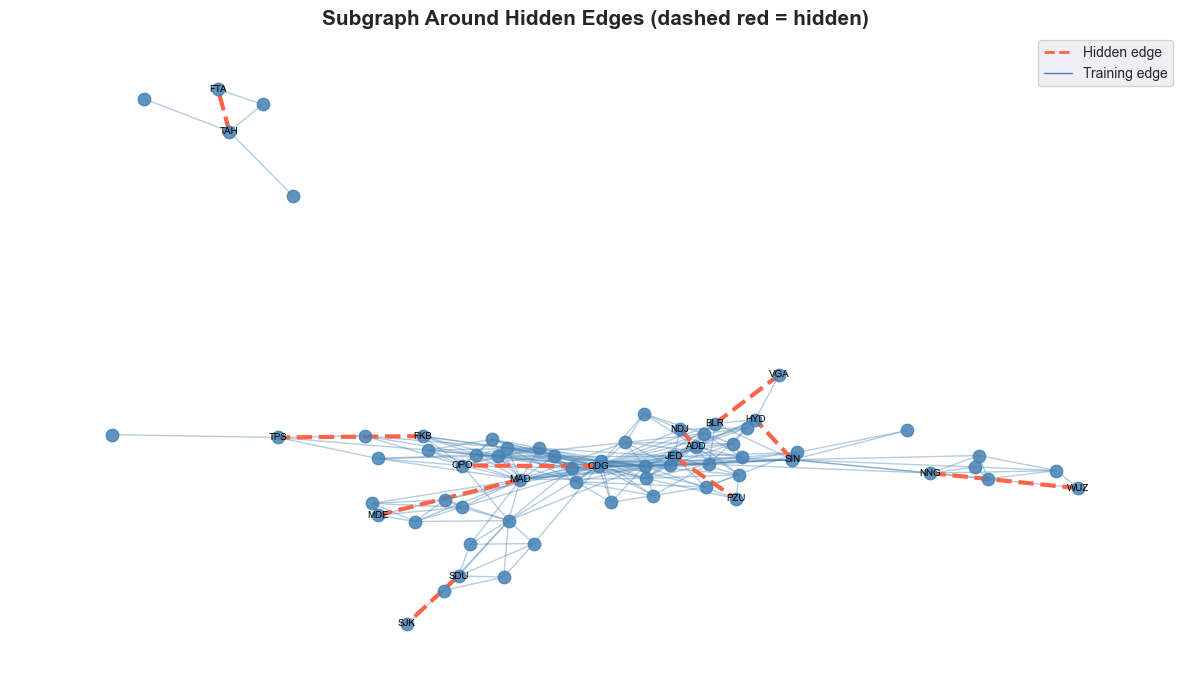

In [27]:
sample_nodes = set()
for u, v in hidden_edges:
    sample_nodes.update([u, v] + list(G.neighbors(u))[:4] + list(G.neighbors(v))[:4])
 
G_sub = G.subgraph(list(sample_nodes)).copy()
pos   = nx.spring_layout(G_sub, seed=SEED)
 
normal_edges = [e for e in G_sub.edges() if set(e) not in
                [set(h) for h in hidden_edges]]
h_edges = [(u, v) for u, v in hidden_edges if G_sub.has_edge(u, v)]
 
fig, ax = plt.subplots(figsize=(12, 7))
nx.draw_networkx_nodes(G_sub, pos, node_size=80, node_color='steelblue', alpha=0.85, ax=ax)
nx.draw_networkx_edges(G_sub, pos, edgelist=normal_edges,
                       edge_color='steelblue', alpha=0.4, width=1, ax=ax)
nx.draw_networkx_edges(G_sub, pos, edgelist=h_edges,
                       edge_color='tomato', width=3, style='dashed',
                       label='Hidden edges', ax=ax)
nx.draw_networkx_labels(G_sub, pos,
                        labels={n: n for n in G_sub.nodes()
                                if n in [u for u, _ in hidden_edges] +
                                   [v for _, v in hidden_edges]},
                        font_size=7, ax=ax)
ax.set_title('Subgraph Around Hidden Edges (dashed red = hidden)')
ax.legend(handles=[
    plt.Line2D([0], [0], color='tomato',     lw=2, ls='--', label='Hidden edge'),
    plt.Line2D([0], [0], color='steelblue',  lw=1, ls='-',  label='Training edge'),
], loc='upper right')
ax.axis('off')

plt.tight_layout()
plt.show()


## Authors:

| Name | NIM | Program Studi |
|---|---|---|
| Jason Yehezkiel Wijaya | 191900531 | IBDA |